In [1]:
# Initialize Notebook 04 independently for leakage-aware split preparation.

from pathlib import Path
import hashlib

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image
from sklearn.model_selection import train_test_split

# Project and dataset paths
PROJECT_ROOT = Path("/Users/krittikaroy/Brain Tumor")
DATASET_ROOT = PROJECT_ROOT / "data" / "brisc2025"
MANIFEST_PATH = DATASET_ROOT / "manifest.csv"

# Output directories
INTERIM_ROOT = PROJECT_ROOT / "data" / "interim"
PROCESSED_ROOT = PROJECT_ROOT / "data" / "processed"
OUTPUTS_ROOT = PROJECT_ROOT / "outputs"

TABLES_ROOT = OUTPUTS_ROOT / "tables"
FIGURES_ROOT = OUTPUTS_ROOT / "figures"

# Create required directories
for folder in [
    INTERIM_ROOT,
    PROCESSED_ROOT,
    TABLES_ROOT,
    FIGURES_ROOT
]:
    folder.mkdir(parents=True, exist_ok=True)

# Normalize manifest paths for macOS
def get_dataset_path(relative_path):
    return DATASET_ROOT / str(relative_path).replace("\\", "/")

# Verify dataset availability
if not MANIFEST_PATH.exists():
    raise FileNotFoundError(
        f"BRISC manifest not found: {MANIFEST_PATH}"
    )

# Load the original manifest independently
manifest_df = pd.read_csv(MANIFEST_PATH)

classification_df = (
    manifest_df[
        manifest_df["task"] == "classification"
    ]
    .copy()
    .reset_index(drop=True)
)

# Verify required columns
required_columns = [
    "relative_path",
    "filename",
    "split",
    "tumor_label",
    "plane_label"
]

missing_columns = [
    col for col in required_columns
    if col not in classification_df.columns
]

if missing_columns:
    raise ValueError(f"Missing columns: {missing_columns}")

print("NOTEBOOK 04 ENVIRONMENT READY")
print("-" * 50)
print("Project:", PROJECT_ROOT)
print("Dataset:", DATASET_ROOT)
print("Manifest records:", len(manifest_df))
print("Classification records:", len(classification_df))

print("\nOfficial split distribution:")
display(classification_df["split"].value_counts())

print("\nOutput directories created successfully.")

NOTEBOOK 04 ENVIRONMENT READY
--------------------------------------------------
Project: /Users/krittikaroy/Brain Tumor
Dataset: /Users/krittikaroy/Brain Tumor/data/brisc2025
Manifest records: 15586
Classification records: 6000

Official split distribution:


split
train    5000
test     1000
Name: count, dtype: int64


Output directories created successfully.


In [2]:
# Generate SHA-256 fingerprints from decoded RGB image content and dimensions.

def decoded_rgb_fingerprint(image_path):
    with Image.open(image_path) as img:
        rgb = img.convert("RGB")
        image_array = np.asarray(rgb)

    height, width = image_array.shape[:2]

    hasher = hashlib.sha256()
    hasher.update(
        f"{width}x{height}|RGB|".encode("utf-8")
    )
    hasher.update(image_array.tobytes())

    return hasher.hexdigest()


fingerprints = []

print("Generating decoded RGB fingerprints...")
print("Images to process:", len(classification_df))

for i, row in classification_df.iterrows():

    image_path = get_dataset_path(row["relative_path"])

    if not image_path.is_file():
        raise FileNotFoundError(f"Image not found: {image_path}")

    fingerprints.append(
        decoded_rgb_fingerprint(image_path)
    )

    if (i + 1) % 500 == 0:
        print(f"Processed {i + 1}/{len(classification_df)}")


classification_df["decoded_rgb_sha256"] = fingerprints

print("\nFINGERPRINTING COMPLETED")
print("-" * 50)
print("Records fingerprinted:", len(fingerprints))
print(
    "Unique decoded fingerprints:",
    classification_df["decoded_rgb_sha256"].nunique()
)

# Save fingerprint records
fingerprint_path = (
    INTERIM_ROOT / "classification_decoded_rgb_fingerprints.csv"
)

classification_df.to_csv(fingerprint_path, index=False)

print("\nFingerprint file saved:", fingerprint_path)

Generating decoded RGB fingerprints...
Images to process: 6000
Processed 500/6000
Processed 1000/6000
Processed 1500/6000
Processed 2000/6000
Processed 2500/6000
Processed 3000/6000
Processed 3500/6000
Processed 4000/6000
Processed 4500/6000
Processed 5000/6000
Processed 5500/6000
Processed 6000/6000

FINGERPRINTING COMPLETED
--------------------------------------------------
Records fingerprinted: 6000
Unique decoded fingerprints: 5856

Fingerprint file saved: /Users/krittikaroy/Brain Tumor/data/interim/classification_decoded_rgb_fingerprints.csv


In [3]:
# Identify duplicate-content groups and detect images shared across official splits.

# Count occurrences of each decoded RGB fingerprint
fingerprint_group_sizes = (
    classification_df.groupby("decoded_rgb_sha256")
    .size()
)

# Identify fingerprints that occur more than once
duplicate_fingerprints = fingerprint_group_sizes[
    fingerprint_group_sizes > 1
].index

duplicate_records_df = classification_df[
    classification_df["decoded_rgb_sha256"].isin(
        duplicate_fingerprints
    )
].copy()

# Summarize each duplicate group
group_split_summary = (
    duplicate_records_df
    .groupby("decoded_rgb_sha256")
    .agg(
        group_size=("filename", "size"),
        train_count=("split", lambda x: (x == "train").sum()),
        test_count=("split", lambda x: (x == "test").sum()),
        label_count=("tumor_label", "nunique")
    )
)

# Categorize duplicate groups
train_only_groups = group_split_summary[
    (group_split_summary["train_count"] > 0) &
    (group_split_summary["test_count"] == 0)
]

test_only_groups = group_split_summary[
    (group_split_summary["train_count"] == 0) &
    (group_split_summary["test_count"] > 0)
]

cross_split_groups = group_split_summary[
    (group_split_summary["train_count"] > 0) &
    (group_split_summary["test_count"] > 0)
]

conflicting_label_groups = group_split_summary[
    group_split_summary["label_count"] > 1
]

# Extract cross-split duplicate records
cross_split_fingerprints = cross_split_groups.index

cross_split_records_df = classification_df[
    classification_df["decoded_rgb_sha256"].isin(
        cross_split_fingerprints
    )
].copy()

cross_split_train_df = cross_split_records_df[
    cross_split_records_df["split"] == "train"
].copy()

cross_split_test_df = cross_split_records_df[
    cross_split_records_df["split"] == "test"
].copy()

# Display results
print("DECODED RGB DUPLICATE ANALYSIS")
print("-" * 55)
print("Total classification images:", len(classification_df))
print("Unique decoded fingerprints:", classification_df["decoded_rgb_sha256"].nunique())
print("Duplicate-content groups:", len(duplicate_fingerprints))
print("Records in duplicate groups:", len(duplicate_records_df))
print("Excess duplicate records:", len(classification_df) - classification_df["decoded_rgb_sha256"].nunique())

print("\nDUPLICATE GROUP DISTRIBUTION")
print("Training-only groups:", len(train_only_groups))
print("Testing-only groups:", len(test_only_groups))
print("Cross-split groups:", len(cross_split_groups))
print("Groups with conflicting tumor labels:", len(conflicting_label_groups))

print("\nCROSS-SPLIT DUPLICATE RECORDS")
print("Affected training records:", len(cross_split_train_df))
print("Affected test records:", len(cross_split_test_df))

print("\nAffected test records by class:")
display(cross_split_test_df["tumor_label"].value_counts())

print("\nAffected training records by class:")
display(cross_split_train_df["tumor_label"].value_counts())

DECODED RGB DUPLICATE ANALYSIS
-------------------------------------------------------
Total classification images: 6000
Unique decoded fingerprints: 5856
Duplicate-content groups: 134
Records in duplicate groups: 278
Excess duplicate records: 144

DUPLICATE GROUP DISTRIBUTION
Training-only groups: 31
Testing-only groups: 5
Cross-split groups: 98
Groups with conflicting tumor labels: 0

CROSS-SPLIT DUPLICATE RECORDS
Affected training records: 104
Affected test records: 101

Affected test records by class:


tumor_label
meningioma    96
pituitary      5
Name: count, dtype: int64


Affected training records by class:


tumor_label
meningioma    97
pituitary      7
Name: count, dtype: int64

In [4]:
# Mark cross-split duplicate records and save the leakage-control audit tables.

# Identify records belonging to cross-split duplicate groups
classification_df["cross_split_duplicate"] = (
    classification_df["decoded_rgb_sha256"].isin(
        cross_split_fingerprints
    )
)

# Mark only affected training records for exclusion
classification_df["exclude_from_training"] = (
    (classification_df["split"] == "train") &
    classification_df["cross_split_duplicate"]
)

# Training records to exclude from model development
training_exclusion_df = classification_df[
    classification_df["exclude_from_training"]
].copy()

# Official test records flagged for audit, but retained
affected_test_audit_df = classification_df[
    (classification_df["split"] == "test") &
    classification_df["cross_split_duplicate"]
].copy()

print("LEAKAGE-CONTROL METADATA")
print("-" * 55)
print("Training records marked for exclusion:", len(training_exclusion_df))
print("Official test records flagged for audit:", len(affected_test_audit_df))
print("Original files deleted:", 0)

# Save audit tables
training_exclusion_path = (
    INTERIM_ROOT / "classification_cross_split_training_exclusions.csv"
)

affected_test_path = (
    INTERIM_ROOT / "classification_cross_split_affected_test_audit.csv"
)

cross_split_group_path = (
    INTERIM_ROOT / "classification_cross_split_decoded_duplicate_groups.csv"
)

training_exclusion_df.to_csv(training_exclusion_path, index=False)
affected_test_audit_df.to_csv(affected_test_path, index=False)

cross_split_groups.reset_index().to_csv(
    cross_split_group_path,
    index=False
)

print("\nAUDIT FILES SAVED")
print("Training exclusions:", training_exclusion_path)
print("Affected test audit:", affected_test_path)
print("Duplicate groups:", cross_split_group_path)

print("\nAll files exist:",
      training_exclusion_path.exists()
      and affected_test_path.exists()
      and cross_split_group_path.exists())

LEAKAGE-CONTROL METADATA
-------------------------------------------------------
Training records marked for exclusion: 104
Official test records flagged for audit: 101
Original files deleted: 0

AUDIT FILES SAVED
Training exclusions: /Users/krittikaroy/Brain Tumor/data/interim/classification_cross_split_training_exclusions.csv
Affected test audit: /Users/krittikaroy/Brain Tumor/data/interim/classification_cross_split_affected_test_audit.csv
Duplicate groups: /Users/krittikaroy/Brain Tumor/data/interim/classification_cross_split_decoded_duplicate_groups.csv

All files exist: True


In [5]:
# Identify remaining duplicate-content groups within the leakage-controlled development pool.

# Keep only official training records not linked to the test set
development_pool_df = classification_df[
    (classification_df["split"] == "train") &
    (~classification_df["exclude_from_training"])
].copy().reset_index(drop=True)

# Summarize remaining duplicate groups
dev_group_summary = (
    development_pool_df
    .groupby("decoded_rgb_sha256")
    .agg(
        group_size=("filename", "size"),
        label_count=("tumor_label", "nunique"),
        plane_count=("plane_label", "nunique")
    )
)

dev_duplicate_groups = dev_group_summary[
    dev_group_summary["group_size"] > 1
].copy()

print("LEAKAGE-CONTROLLED DEVELOPMENT POOL")
print("-" * 55)
print("Original training records:", 5000)
print("Cross-split exclusions:", len(training_exclusion_df))
print("Remaining development records:", len(development_pool_df))
print("Unique decoded fingerprints:",
      development_pool_df["decoded_rgb_sha256"].nunique())

print("\nWITHIN-DEVELOPMENT DUPLICATE AUDIT")
print("-" * 55)
print("Duplicate groups:", len(dev_duplicate_groups))
print("Records in duplicate groups:",
      int(dev_duplicate_groups["group_size"].sum()))
print("Excess duplicate records:",
      int((dev_duplicate_groups["group_size"] - 1).sum()))
print("Groups with conflicting tumor labels:",
      int((dev_duplicate_groups["label_count"] > 1).sum()))
print("Groups with conflicting MRI-plane labels:",
      int((dev_duplicate_groups["plane_count"] > 1).sum()))

print("\nDUPLICATE GROUP SIZE DISTRIBUTION")
display(
    dev_duplicate_groups["group_size"]
    .value_counts()
    .sort_index()
    .rename("number_of_groups")
    .to_frame()
)

print("\nDEVELOPMENT POOL BY CLASS")
display(
    development_pool_df["tumor_label"]
    .value_counts()
    .sort_index()
    .rename("records")
    .to_frame()
)

print("\nDEVELOPMENT POOL BY CLASS AND MRI PLANE")
display(
    pd.crosstab(
        development_pool_df["tumor_label"],
        development_pool_df["plane_label"]
    )
)

LEAKAGE-CONTROLLED DEVELOPMENT POOL
-------------------------------------------------------
Original training records: 5000
Cross-split exclusions: 104
Remaining development records: 4896
Unique decoded fingerprints: 4864

WITHIN-DEVELOPMENT DUPLICATE AUDIT
-------------------------------------------------------
Duplicate groups: 31
Records in duplicate groups: 63
Excess duplicate records: 32
Groups with conflicting tumor labels: 0
Groups with conflicting MRI-plane labels: 11

DUPLICATE GROUP SIZE DISTRIBUTION


,number_of_groups
group_size,
2,30
3,1



DEVELOPMENT POOL BY CLASS


,records
tumor_label,
glioma,1147
meningioma,1232
no_tumor,1067
pituitary,1450



DEVELOPMENT POOL BY CLASS AND MRI PLANE


plane_label,axial,coronal,sagittal
tumor_label,,,
glioma,394,430,323
meningioma,361,407,464
no_tumor,352,310,405
pituitary,424,505,521


In [6]:
# Identify and inspect duplicate image groups with conflicting MRI-plane metadata.

plane_conflict_fingerprints = dev_duplicate_groups[
    dev_duplicate_groups["plane_count"] > 1
].index

plane_conflict_records_df = development_pool_df[
    development_pool_df["decoded_rgb_sha256"].isin(
        plane_conflict_fingerprints
    )
].copy()

# Create a readable group summary
plane_conflict_summary = (
    plane_conflict_records_df
    .groupby("decoded_rgb_sha256")
    .agg(
        records=("filename", "size"),
        tumor_label=("tumor_label", "first"),
        planes=(
            "plane_label",
            lambda x: ", ".join(sorted(set(x)))
        ),
        filenames=("filename", list)
    )
    .reset_index()
)

plane_conflict_summary["fingerprint_short"] = (
    plane_conflict_summary["decoded_rgb_sha256"].str[:12]
)

print("MRI-PLANE CONFLICT AUDIT")
print("-" * 55)
print("Conflicting duplicate groups:", len(plane_conflict_fingerprints))
print("Records involved:", len(plane_conflict_records_df))

display(
    plane_conflict_summary[
        ["fingerprint_short", "records", "tumor_label", "planes", "filenames"]
    ]
)

# Save the detailed conflict records
conflict_path = (
    INTERIM_ROOT / "classification_duplicate_plane_conflicts.csv"
)

plane_conflict_records_df.to_csv(conflict_path, index=False)

print("\nConflict audit saved:", conflict_path)

MRI-PLANE CONFLICT AUDIT
-------------------------------------------------------
Conflicting duplicate groups: 11
Records involved: 22


,fingerprint_short,records,tumor_label,planes,filenames
0,1cb1d65c83ca,2,meningioma,"axial, coronal","[brisc2025_train_01238_me_ax_t1.jpg, brisc2025..."
1,36be02c612f1,2,meningioma,"axial, sagittal","[brisc2025_train_01467_me_ax_t1.jpg, brisc2025..."
2,38976d58721e,2,meningioma,"coronal, sagittal","[brisc2025_train_01571_me_co_t1.jpg, brisc2025..."
3,5f186e7e7543,2,meningioma,"axial, sagittal","[brisc2025_train_01456_me_ax_t1.jpg, brisc2025..."
4,7bdd320367fa,2,meningioma,"axial, coronal","[brisc2025_train_01240_me_ax_t1.jpg, brisc2025..."
5,9ce7f1c1ba1b,2,meningioma,"axial, coronal","[brisc2025_train_01251_me_ax_t1.jpg, brisc2025..."
6,abc0b54c1caf,2,meningioma,"axial, sagittal","[brisc2025_train_01469_me_ax_t1.jpg, brisc2025..."
7,bbeb9d74b258,2,meningioma,"axial, coronal","[brisc2025_train_01442_me_ax_t1.jpg, brisc2025..."
8,c361f52bf37f,2,meningioma,"axial, coronal","[brisc2025_train_01239_me_ax_t1.jpg, brisc2025..."
9,ca7caae35246,2,meningioma,"axial, coronal","[brisc2025_train_01237_me_ax_t1.jpg, brisc2025..."



Conflict audit saved: /Users/krittikaroy/Brain Tumor/data/interim/classification_duplicate_plane_conflicts.csv


In [7]:
# Retain one deterministic representative per unique image and record duplicate exclusions.

# 1. Create group-level metadata
content_group_metadata = (
    development_pool_df
    .groupby("decoded_rgb_sha256")
    .agg(
        source_record_count=("filename", "size"),
        tumor_label_count=("tumor_label", "nunique"),
        plane_label_count=("plane_label", "nunique"),
        observed_tumor_labels=(
            "tumor_label",
            lambda x: ", ".join(sorted(set(x.dropna().astype(str))))
        ),
        observed_plane_labels=(
            "plane_label",
            lambda x: ", ".join(sorted(set(x.dropna().astype(str))))
        )
    )
    .reset_index()
)

content_group_metadata["plane_metadata_conflict"] = (
    content_group_metadata["plane_label_count"] > 1
)

# Do not proceed if identical images have conflicting tumor labels
if (content_group_metadata["tumor_label_count"] > 1).any():
    raise ValueError("Conflicting tumor labels found in duplicate groups.")

# 2. Deterministically select one representative per fingerprint
sorted_dev_df = development_pool_df.sort_values(
    ["decoded_rgb_sha256", "relative_path"]
).copy()

unique_development_df = sorted_dev_df.drop_duplicates(
    subset="decoded_rgb_sha256",
    keep="first"
).copy()

# 3. Attach group-level audit metadata
unique_development_df = unique_development_df.merge(
    content_group_metadata[
        [
            "decoded_rgb_sha256",
            "source_record_count",
            "observed_plane_labels",
            "plane_metadata_conflict"
        ]
    ],
    on="decoded_rgb_sha256",
    how="left",
    validate="one_to_one"
)

# Use a conflict category instead of guessing the MRI plane
unique_development_df["plane_for_stratification"] = np.where(
    unique_development_df["plane_metadata_conflict"],
    "conflict",
    unique_development_df["plane_label"]
)

# 4. Identify records not retained
retained_paths = set(unique_development_df["relative_path"])

within_dev_duplicate_exclusions_df = development_pool_df[
    ~development_pool_df["relative_path"].isin(retained_paths)
].copy()

within_dev_duplicate_exclusions_df["exclusion_reason"] = (
    "redundant_exact_duplicate_within_development_pool"
)

# 5. Display results
print("UNIQUE-CONTENT DEVELOPMENT POOL")
print("-" * 55)
print("Input development records:", len(development_pool_df))
print("Unique-content representatives:", len(unique_development_df))
print("Redundant records excluded:",
      len(within_dev_duplicate_exclusions_df))
print("Plane-conflict representatives:",
      int(unique_development_df["plane_metadata_conflict"].sum()))

print("\nCLASS DISTRIBUTION")
display(
    unique_development_df["tumor_label"]
    .value_counts()
    .sort_index()
    .rename("records")
    .to_frame()
)

print("\nPLANE CATEGORY FOR STRATIFICATION")
display(
    unique_development_df["plane_for_stratification"]
    .value_counts()
    .sort_index()
    .rename("records")
    .to_frame()
)

# 6. Save the unique pool and exclusion records
within_dev_exclusion_path = (
    INTERIM_ROOT /
    "classification_within_development_duplicate_exclusions.csv"
)

unique_dev_path = (
    INTERIM_ROOT /
    "classification_unique_content_development_pool.csv"
)

plane_conflict_path = (
    INTERIM_ROOT /
    "classification_duplicate_plane_conflicts.csv"
)

within_dev_duplicate_exclusions_df.to_csv(
    within_dev_exclusion_path, index=False
)

unique_development_df.to_csv(unique_dev_path, index=False)

plane_conflict_records_df.to_csv(
    plane_conflict_path, index=False
)

# 7. Final checks
assert unique_development_df["decoded_rgb_sha256"].is_unique
assert len(development_pool_df) == (
    len(unique_development_df)
    + len(within_dev_duplicate_exclusions_df)
)

print("\nFILES SAVED")
print("Unique development pool:", unique_dev_path.exists())
print("Within-development exclusions:", within_dev_exclusion_path.exists())
print("Plane-conflict audit:", plane_conflict_path.exists())

print("\nUnique-content development pool created successfully.")

UNIQUE-CONTENT DEVELOPMENT POOL
-------------------------------------------------------
Input development records: 4896
Unique-content representatives: 4864
Redundant records excluded: 32
Plane-conflict representatives: 11

CLASS DISTRIBUTION


,records
tumor_label,
glioma,1147
meningioma,1219
no_tumor,1058
pituitary,1440



PLANE CATEGORY FOR STRATIFICATION


,records
plane_for_stratification,
axial,1520
conflict,11
coronal,1642
sagittal,1691



FILES SAVED
Unique development pool: True
Within-development exclusions: True
Plane-conflict audit: True

Unique-content development pool created successfully.


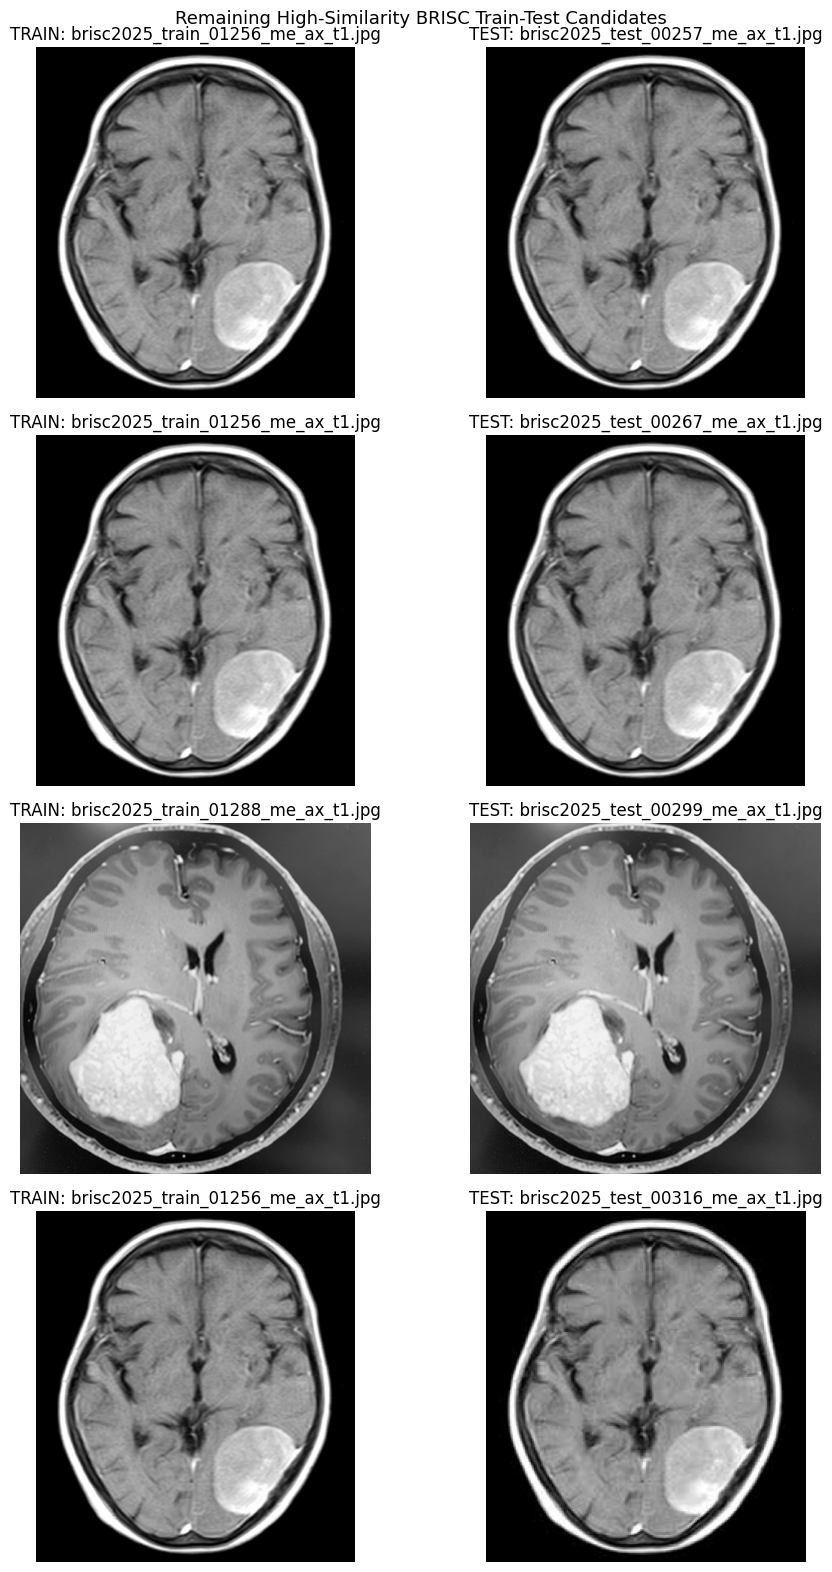

NATIVE-RESOLUTION VERIFICATION
------------------------------------------------------------


,train_filename,test_filename,train_shape,test_shape,same_native_shape,pixel_identical_native,native_rmse,native_correlation,differing_rgb_pixels,phash_distance,normalized_rmse,normalized_correlation
0,brisc2025_train_01256_me_ax_t1.jpg,brisc2025_test_00257_me_ax_t1.jpg,"(650, 591, 3)","(581, 528, 3)",False,False,NaN,NaN,NaN,0,0.004325,0.999897
1,brisc2025_train_01256_me_ax_t1.jpg,brisc2025_test_00267_me_ax_t1.jpg,"(650, 591, 3)","(650, 591, 3)",True,False,0.006491,0.999804,216181.0,0,0.005852,0.999842
2,brisc2025_train_01288_me_ax_t1.jpg,brisc2025_test_00299_me_ax_t1.jpg,"(480, 480, 3)","(480, 480, 3)",True,False,0.009696,0.999664,164455.0,0,0.009460,0.999696
3,brisc2025_train_01256_me_ax_t1.jpg,brisc2025_test_00316_me_ax_t1.jpg,"(650, 591, 3)","(235, 214, 3)",False,False,NaN,NaN,NaN,2,0.012262,0.999176



SUMMARY
Pairs checked: 4
Same native dimensions: 2
Different native dimensions: 2
Pixel-identical pairs: 0


In [8]:
# Verify the four remaining high-similarity train-test candidates using your actual BRISC images.

# Four candidates retained after the original exact-duplicate cleaning
candidate_pairs = [
    {
        "train_filename": "brisc2025_train_01256_me_ax_t1.jpg",
        "test_filename": "brisc2025_test_00257_me_ax_t1.jpg",
        "phash_distance": 0,
        "normalized_rmse": 0.004325,
        "normalized_correlation": 0.999897
    },
    {
        "train_filename": "brisc2025_train_01256_me_ax_t1.jpg",
        "test_filename": "brisc2025_test_00267_me_ax_t1.jpg",
        "phash_distance": 0,
        "normalized_rmse": 0.005852,
        "normalized_correlation": 0.999842
    },
    {
        "train_filename": "brisc2025_train_01288_me_ax_t1.jpg",
        "test_filename": "brisc2025_test_00299_me_ax_t1.jpg",
        "phash_distance": 0,
        "normalized_rmse": 0.009460,
        "normalized_correlation": 0.999696
    },
    {
        "train_filename": "brisc2025_train_01256_me_ax_t1.jpg",
        "test_filename": "brisc2025_test_00316_me_ax_t1.jpg",
        "phash_distance": 2,
        "normalized_rmse": 0.012262,
        "normalized_correlation": 0.999176
    }
]

candidate_df = pd.DataFrame(candidate_pairs)

# Prepare filename lookup
filename_lookup = classification_df.set_index("filename")

verification_records = []

fig, axes = plt.subplots(4, 2, figsize=(10, 16))

for i, row in candidate_df.iterrows():

    train_name = row["train_filename"]
    test_name = row["test_filename"]

    # Verify that both filenames exist
    if train_name not in filename_lookup.index:
        raise ValueError(f"Training image not found: {train_name}")

    if test_name not in filename_lookup.index:
        raise ValueError(f"Test image not found: {test_name}")

    train_row = filename_lookup.loc[train_name]
    test_row = filename_lookup.loc[test_name]

    # Verify official splits and development-pool membership
    assert train_row["split"] == "train"
    assert test_row["split"] == "test"

    assert train_name in set(unique_development_df["filename"])

    train_path = get_dataset_path(train_row["relative_path"])
    test_path = get_dataset_path(test_row["relative_path"])

    with Image.open(train_path) as img:
        train_rgb = np.asarray(img.convert("RGB"))

    with Image.open(test_path) as img:
        test_rgb = np.asarray(img.convert("RGB"))

    same_shape = train_rgb.shape == test_rgb.shape

    native_rmse = np.nan
    native_correlation = np.nan
    differing_pixels = np.nan

    if same_shape:

        pixel_identical = np.array_equal(train_rgb, test_rgb)

        train_float = train_rgb.astype(np.float32) / 255.0
        test_float = test_rgb.astype(np.float32) / 255.0

        native_rmse = float(
            np.sqrt(np.mean((train_float - test_float) ** 2))
        )

        native_correlation = float(
            np.corrcoef(
                train_float.ravel(),
                test_float.ravel()
            )[0, 1]
        )

        differing_pixels = int(
            np.any(train_rgb != test_rgb, axis=2).sum()
        )

    else:
        pixel_identical = False

    verification_records.append({
        "train_filename": train_name,
        "test_filename": test_name,
        "train_shape": str(train_rgb.shape),
        "test_shape": str(test_rgb.shape),
        "same_native_shape": same_shape,
        "pixel_identical_native": pixel_identical,
        "native_rmse": native_rmse,
        "native_correlation": native_correlation,
        "differing_rgb_pixels": differing_pixels,
        "phash_distance": row["phash_distance"],
        "normalized_rmse": row["normalized_rmse"],
        "normalized_correlation": row["normalized_correlation"]
    })

    # Display the actual image pairs
    axes[i, 0].imshow(train_rgb)
    axes[i, 0].set_title(f"TRAIN: {train_name}")
    axes[i, 0].axis("off")

    axes[i, 1].imshow(test_rgb)
    axes[i, 1].set_title(f"TEST: {test_name}")
    axes[i, 1].axis("off")

plt.suptitle(
    "Remaining High-Similarity BRISC Train-Test Candidates",
    fontsize=13
)

plt.tight_layout()

plt.savefig(
    FIGURES_ROOT / "audit_remaining_similarity_candidates.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Display verification results
native_verification_df = pd.DataFrame(verification_records)

print("NATIVE-RESOLUTION VERIFICATION")
print("-" * 60)
display(native_verification_df)

print("\nSUMMARY")
print("Pairs checked:", len(native_verification_df))
print(
    "Same native dimensions:",
    int(native_verification_df["same_native_shape"].sum())
)
print(
    "Different native dimensions:",
    int((~native_verification_df["same_native_shape"]).sum())
)
print(
    "Pixel-identical pairs:",
    int(native_verification_df["pixel_identical_native"].sum())
)

In [9]:
# Exclude the two visually reviewed near-duplicate training images from the development pool.

# Training images identified in your friend's verified analysis
derivative_exclusion_filenames = {
    "brisc2025_train_01256_me_ax_t1.jpg",
    "brisc2025_train_01288_me_ax_t1.jpg"
}

# Identify the two records in the unique development pool
derivative_exclusion_df = unique_development_df[
    unique_development_df["filename"].isin(
        derivative_exclusion_filenames
    )
].copy()

# Verify that both expected training images were found
found_filenames = set(derivative_exclusion_df["filename"])

if found_filenames != derivative_exclusion_filenames:
    raise ValueError(
        "The expected derivative training images were not found. "
        f"Found: {found_filenames}"
    )

if not (derivative_exclusion_df["tumor_label"] == "meningioma").all():
    raise ValueError("Unexpected tumor class in derivative exclusions.")

derivative_exclusion_df["exclusion_reason"] = (
    "confirmed_high_similarity_derivative_overlap_with_official_test"
)

print("DERIVATIVE / NEAR-DUPLICATE EXCLUSIONS")
print("-" * 55)
display(
    derivative_exclusion_df[
        ["filename", "tumor_label", "plane_label", "exclusion_reason"]
    ]
)

# Create the final leakage-controlled development pool
final_development_df = unique_development_df[
    ~unique_development_df["filename"].isin(
        derivative_exclusion_filenames
    )
].copy().reset_index(drop=True)

# Verify final development pool
print("\nFINAL DEVELOPMENT POOL")
print("-" * 55)
print("Before derivative exclusions:", len(unique_development_df))
print("Derivative exclusions:", len(derivative_exclusion_df))
print("Final development records:", len(final_development_df))
print(
    "Unique decoded fingerprints:",
    final_development_df["decoded_rgb_sha256"].nunique()
)

print("\nFINAL CLASS DISTRIBUTION")
display(
    final_development_df["tumor_label"]
    .value_counts()
    .sort_index()
    .rename("records")
    .to_frame()
)

# Save exclusion and final development records
derivative_exclusion_path = (
    INTERIM_ROOT /
    "classification_confirmed_derivative_training_exclusions.csv"
)

final_dev_path = (
    INTERIM_ROOT /
    "classification_final_leakage_controlled_development_pool.csv"
)

remaining_candidate_audit_path = (
    INTERIM_ROOT /
    "classification_remaining_similarity_candidate_audit.csv"
)

derivative_exclusion_df.to_csv(
    derivative_exclusion_path, index=False
)

final_development_df.to_csv(
    final_dev_path, index=False
)

native_verification_df.to_csv(
    remaining_candidate_audit_path, index=False
)

print("\nAudit files saved successfully.")

# Final assertions
assert len(derivative_exclusion_df) == 2
assert len(final_development_df) == 4862
assert final_development_df["decoded_rgb_sha256"].is_unique

print("All development-pool checks passed.")

DERIVATIVE / NEAR-DUPLICATE EXCLUSIONS
-------------------------------------------------------


,filename,tumor_label,plane_label,exclusion_reason
726,brisc2025_train_01288_me_ax_t1.jpg,meningioma,axial,confirmed_high_similarity_derivative_overlap_w...
4666,brisc2025_train_01256_me_ax_t1.jpg,meningioma,axial,confirmed_high_similarity_derivative_overlap_w...



FINAL DEVELOPMENT POOL
-------------------------------------------------------
Before derivative exclusions: 4864
Derivative exclusions: 2
Final development records: 4862
Unique decoded fingerprints: 4862

FINAL CLASS DISTRIBUTION


,records
tumor_label,
glioma,1147
meningioma,1217
no_tumor,1058
pituitary,1440



Audit files saved successfully.
All development-pool checks passed.


In [10]:
# Verify the final development pool before constructing training and validation splits.

# Load the unchanged official test records from the original manifest
official_test_df = classification_df[
    classification_df["split"] == "test"
].copy()

print("PRE-SPLIT SANITY VERIFICATION")
print("-" * 60)

# 1. Final development pool size
print("Final development records:", len(final_development_df))

# 2. Check decoded-content uniqueness
unique_dev_fingerprints = (
    final_development_df["decoded_rgb_sha256"].nunique()
)

print("Unique development fingerprints:", unique_dev_fingerprints)
print("Duplicate fingerprints remaining:",
      len(final_development_df) - unique_dev_fingerprints)

# 3. Check exact-content overlap with official test
development_fingerprints = set(
    final_development_df["decoded_rgb_sha256"]
)

test_fingerprints = set(
    official_test_df["decoded_rgb_sha256"]
)

residual_exact_overlap = (
    development_fingerprints & test_fingerprints
)

print("Residual exact-content overlap with test:",
      len(residual_exact_overlap))

# 4. Check excluded derivative images
remaining_derivative_records = final_development_df[
    final_development_df["filename"].isin(
        derivative_exclusion_filenames
    )
]

print("Excluded derivative records still present:",
      len(remaining_derivative_records))

# 5. Check missing metadata
print("Missing tumor labels:",
      final_development_df["tumor_label"].isna().sum())

print("Missing MRI-plane labels:",
      final_development_df["plane_for_stratification"].isna().sum())

# 6. Create composite stratification label
final_development_df["stratification_label"] = (
    final_development_df["tumor_label"].astype(str)
    + "__"
    + final_development_df["plane_for_stratification"].astype(str)
)

stratum_counts = (
    final_development_df["stratification_label"]
    .value_counts()
    .sort_index()
)

print("\nCLASS × PLANE STRATIFICATION COUNTS")
print("-" * 60)
display(stratum_counts.rename("records").to_frame())

print("Number of strata:", len(stratum_counts))
print("Smallest stratum:", int(stratum_counts.min()))

# 7. Final verification assertions
assert len(final_development_df) == 4862
assert unique_dev_fingerprints == 4862
assert len(residual_exact_overlap) == 0
assert len(remaining_derivative_records) == 0
assert final_development_df["tumor_label"].isna().sum() == 0
assert final_development_df["plane_for_stratification"].isna().sum() == 0
assert stratum_counts.min() >= 2

print("\nALL PRE-SPLIT SANITY CHECKS PASSED.")

PRE-SPLIT SANITY VERIFICATION
------------------------------------------------------------
Final development records: 4862
Unique development fingerprints: 4862
Duplicate fingerprints remaining: 0
Residual exact-content overlap with test: 0
Excluded derivative records still present: 0
Missing tumor labels: 0
Missing MRI-plane labels: 0

CLASS × PLANE STRATIFICATION COUNTS
------------------------------------------------------------


,records
stratification_label,
glioma__axial,394
glioma__coronal,430
glioma__sagittal,323
meningioma__axial,348
meningioma__conflict,11
meningioma__coronal,400
meningioma__sagittal,458
no_tumor__axial,352
no_tumor__coronal,310


Number of strata: 13
Smallest stratum: 11

ALL PRE-SPLIT SANITY CHECKS PASSED.


In [11]:
# Create reproducible stratified training and validation splits and compare their distributions.

RANDOM_SEED = 42
VALIDATION_FRACTION = 0.20

# Create the stratified split
train_df, validation_df = train_test_split(
    final_development_df,
    test_size=VALIDATION_FRACTION,
    random_state=RANDOM_SEED,
    stratify=final_development_df["stratification_label"]
)

train_df = train_df.copy().reset_index(drop=True)
validation_df = validation_df.copy().reset_index(drop=True)

train_df["model_split"] = "train"
validation_df["model_split"] = "validation"

# Display split summary
print("REPRODUCIBLE TRAIN / VALIDATION SPLIT")
print("-" * 60)
print("Random seed:", RANDOM_SEED)
print("Validation fraction:", VALIDATION_FRACTION)
print("Development pool:", len(final_development_df))
print("Training records:", len(train_df))
print("Validation records:", len(validation_df))
print("Total records:", len(train_df) + len(validation_df))

# Compare tumor-class distributions
train_class_counts = train_df["tumor_label"].value_counts().sort_index()
validation_class_counts = validation_df["tumor_label"].value_counts().sort_index()

class_comparison_df = pd.DataFrame({
    "train_records": train_class_counts,
    "validation_records": validation_class_counts,
    "train_percent": train_class_counts / len(train_df) * 100,
    "validation_percent": validation_class_counts / len(validation_df) * 100
})

class_comparison_df["absolute_difference"] = (
    class_comparison_df["train_percent"]
    - class_comparison_df["validation_percent"]
).abs()

print("\nCLASS DISTRIBUTION COMPARISON")
display(class_comparison_df.round(3))

# Compare composite class and MRI-plane stratification
strata_comparison_df = pd.concat([
    train_df["stratification_label"].value_counts().rename("train_records"),
    validation_df["stratification_label"].value_counts().rename("validation_records")
], axis=1).fillna(0).astype(int)

strata_comparison_df["total"] = (
    strata_comparison_df["train_records"]
    + strata_comparison_df["validation_records"]
)

print("\nCLASS × MRI-PLANE STRATIFICATION")
display(strata_comparison_df)

# Verify split sizes and class coverage
assert len(train_df) == 3889
assert len(validation_df) == 973
assert len(train_df) + len(validation_df) == 4862

assert set(train_df["tumor_label"]) == set(validation_df["tumor_label"])

print("\n80:20 STRATIFIED SPLIT CREATED SUCCESSFULLY.")

REPRODUCIBLE TRAIN / VALIDATION SPLIT
------------------------------------------------------------
Random seed: 42
Validation fraction: 0.2
Development pool: 4862
Training records: 3889
Validation records: 973
Total records: 4862

CLASS DISTRIBUTION COMPARISON


,train_records,validation_records,train_percent,validation_percent,absolute_difference
tumor_label,,,,,
glioma,917,230,23.579,23.638,0.059
meningioma,973,244,25.019,25.077,0.058
no_tumor,847,211,21.779,21.686,0.094
pituitary,1152,288,29.622,29.599,0.023



CLASS × MRI-PLANE STRATIFICATION


,train_records,validation_records,total
stratification_label,,,
pituitary__sagittal,411,103,514
pituitary__coronal,402,100,502
meningioma__sagittal,366,92,458
glioma__coronal,344,86,430
pituitary__axial,339,85,424
meningioma__coronal,320,80,400
no_tumor__sagittal,317,79,396
glioma__axial,315,79,394
no_tumor__axial,282,70,352



80:20 STRATIFIED SPLIT CREATED SUCCESSFULLY.


In [12]:
# Compare tumor-class and MRI-plane distributions across training and validation splits.

# 1. Tumor-class distribution
class_split_table = pd.crosstab(
    final_classification_split_label if False else train_df["tumor_label"],
    train_df["model_split"]
) if False else pd.DataFrame({
    "train_records": train_df["tumor_label"].value_counts(),
    "validation_records": validation_df["tumor_label"].value_counts()
}).fillna(0).astype(int)

class_split_table["train_percent"] = (
    class_split_table["train_records"] / len(train_df) * 100
)

class_split_table["validation_percent"] = (
    class_split_table["validation_records"] / len(validation_df) * 100
)

print("CLASS DISTRIBUTION — TRAIN AND VALIDATION")
print("-" * 60)
display(class_split_table.round(3))

# 2. Class × MRI-plane distribution
train_strata = (
    train_df["stratification_label"]
    .value_counts()
    .rename("train_records")
)

validation_strata = (
    validation_df["stratification_label"]
    .value_counts()
    .rename("validation_records")
)

strata_split_table = pd.concat(
    [train_strata, validation_strata],
    axis=1
).fillna(0).astype(int)

print("\nCLASS × MRI-PLANE DISTRIBUTION")
print("-" * 60)
display(strata_split_table)

# 3. Save distribution tables
class_split_table.to_csv(
    TABLES_ROOT / "classification_train_validation_class_distribution.csv"
)

strata_split_table.to_csv(
    TABLES_ROOT / "classification_train_validation_class_plane_distribution.csv"
)

print("\nDistribution tables saved successfully.")

CLASS DISTRIBUTION — TRAIN AND VALIDATION
------------------------------------------------------------


,train_records,validation_records,train_percent,validation_percent
tumor_label,,,,
pituitary,1152,288,29.622,29.599
meningioma,973,244,25.019,25.077
glioma,917,230,23.579,23.638
no_tumor,847,211,21.779,21.686



CLASS × MRI-PLANE DISTRIBUTION
------------------------------------------------------------


,train_records,validation_records
stratification_label,,
pituitary__sagittal,411,103
pituitary__coronal,402,100
meningioma__sagittal,366,92
glioma__coronal,344,86
pituitary__axial,339,85
meningioma__coronal,320,80
no_tumor__sagittal,317,79
glioma__axial,315,79
no_tumor__axial,282,70



Distribution tables saved successfully.


In [13]:
# Verify that training, validation and official test splits have no shared image content.

# 1. Create fingerprint sets
train_fingerprints = set(train_df["decoded_rgb_sha256"])
validation_fingerprints = set(validation_df["decoded_rgb_sha256"])
official_test_fingerprints = set(official_test_df["decoded_rgb_sha256"])

# 2. Check pairwise decoded-content overlap
train_validation_overlap = (
    train_fingerprints & validation_fingerprints
)

train_test_overlap = (
    train_fingerprints & official_test_fingerprints
)

validation_test_overlap = (
    validation_fingerprints & official_test_fingerprints
)

# 3. Check relative-path overlap
train_paths = set(train_df["relative_path"])
validation_paths = set(validation_df["relative_path"])
test_paths = set(official_test_df["relative_path"])

train_validation_path_overlap = train_paths & validation_paths
train_test_path_overlap = train_paths & test_paths
validation_test_path_overlap = validation_paths & test_paths

# 4. Display results
print("FINAL CONTENT-LEAKAGE VERIFICATION")
print("-" * 60)

print("Training records:", len(train_df))
print("Validation records:", len(validation_df))
print("Official test records:", len(official_test_df))

print("\nDECODED-CONTENT OVERLAP")
print("Train ↔ Validation:", len(train_validation_overlap))
print("Train ↔ Official Test:", len(train_test_overlap))
print("Validation ↔ Official Test:", len(validation_test_overlap))

print("\nFILE-PATH OVERLAP")
print("Train ↔ Validation:", len(train_validation_path_overlap))
print("Train ↔ Test:", len(train_test_path_overlap))
print("Validation ↔ Test:", len(validation_test_path_overlap))

# 5. Confirm the official test split is unchanged
original_test_paths = set(
    classification_df.loc[
        classification_df["split"] == "test",
        "relative_path"
    ]
)

print("\nOFFICIAL TEST PRESERVATION")
print("Original test records:", len(original_test_paths))
print("Current test records:", len(test_paths))
print("Test membership unchanged:", original_test_paths == test_paths)

# 6. Hard verification checks
assert len(train_df) == 3889
assert len(validation_df) == 973
assert len(official_test_df) == 1000

assert len(train_validation_overlap) == 0
assert len(train_test_overlap) == 0
assert len(validation_test_overlap) == 0

assert len(train_validation_path_overlap) == 0
assert len(train_test_path_overlap) == 0
assert len(validation_test_path_overlap) == 0

assert original_test_paths == test_paths

print("\nALL FINAL LEAKAGE CHECKS PASSED.")

FINAL CONTENT-LEAKAGE VERIFICATION
------------------------------------------------------------
Training records: 3889
Validation records: 973
Official test records: 1000

DECODED-CONTENT OVERLAP
Train ↔ Validation: 0
Train ↔ Official Test: 0
Validation ↔ Official Test: 0

FILE-PATH OVERLAP
Train ↔ Validation: 0
Train ↔ Test: 0
Validation ↔ Test: 0

OFFICIAL TEST PRESERVATION
Original test records: 1000
Current test records: 1000
Test membership unchanged: True

ALL FINAL LEAKAGE CHECKS PASSED.


In [14]:
# Export the definitive train, validation, test manifests and training exclusion ledger.

# 1. Prepare the three final manifests
final_train_manifest = train_df.copy()

final_validation_manifest = validation_df.copy()

final_test_manifest = official_test_df.copy()
final_test_manifest["model_split"] = "test"

# Keep a consistent stratification field in the official test manifest
final_test_manifest["plane_for_stratification"] = (
    final_test_manifest["plane_label"]
)

final_test_manifest["stratification_label"] = (
    final_test_manifest["tumor_label"].astype(str)
    + "__"
    + final_test_manifest["plane_for_stratification"].astype(str)
)

# 2. Define output paths
train_manifest_path = (
    PROCESSED_ROOT / "classification_train_manifest.csv"
)

validation_manifest_path = (
    PROCESSED_ROOT / "classification_validation_manifest.csv"
)

test_manifest_path = (
    PROCESSED_ROOT / "classification_test_manifest.csv"
)

master_split_path = (
    PROCESSED_ROOT / "classification_final_split_manifest.csv"
)

exclusion_ledger_path = (
    PROCESSED_ROOT / "classification_training_exclusion_ledger.csv"
)

# 3. Save individual manifests
final_train_manifest.to_csv(train_manifest_path, index=False)

final_validation_manifest.to_csv(
    validation_manifest_path, index=False
)

final_test_manifest.to_csv(test_manifest_path, index=False)

# 4. Create combined master manifest
final_classification_split_manifest = pd.concat(
    [
        final_train_manifest,
        final_validation_manifest,
        final_test_manifest
    ],
    ignore_index=True
)

final_classification_split_manifest.to_csv(
    master_split_path, index=False
)

# 5. Build unified training-exclusion ledger
exact_cross_test_exclusions = training_exclusion_df.copy()
exact_cross_test_exclusions["exclusion_reason"] = (
    "exact_decoded_content_overlap_with_official_test"
)

within_train_exclusions = within_dev_duplicate_exclusions_df.copy()
within_train_exclusions["exclusion_reason"] = (
    "redundant_exact_duplicate_within_development_pool"
)

derivative_exclusions = derivative_exclusion_df.copy()
derivative_exclusions["exclusion_reason"] = (
    "confirmed_high_similarity_derivative_overlap_with_official_test"
)

exclusion_ledger_df = pd.concat(
    [
        exact_cross_test_exclusions,
        within_train_exclusions,
        derivative_exclusions
    ],
    ignore_index=True
)

# Verify that the exclusion ledger contains unique original records
if exclusion_ledger_df["relative_path"].duplicated().any():
    raise ValueError("Duplicate paths found in the exclusion ledger.")

exclusion_ledger_df.to_csv(
    exclusion_ledger_path, index=False
)

# 6. Display export summary
print("FINAL MANIFEST EXPORT")
print("-" * 60)

print("Training records:", len(final_train_manifest))
print("Validation records:", len(final_validation_manifest))
print("Official test records:", len(final_test_manifest))
print("Combined retained records:", len(final_classification_split_manifest))

print("\nEXCLUSION LEDGER")
display(
    exclusion_ledger_df["exclusion_reason"]
    .value_counts()
    .rename("excluded_records")
    .to_frame()
)

print("\nTotal excluded training records:", len(exclusion_ledger_df))

# 7. Confirm files were saved
exported_files = [
    train_manifest_path,
    validation_manifest_path,
    test_manifest_path,
    master_split_path,
    exclusion_ledger_path
]

print("\nEXPORTED FILES")
for file_path in exported_files:
    print(file_path.name, "—", "Saved" if file_path.exists() else "Missing")

# 8. Basic count assertions
assert len(final_train_manifest) == 3889
assert len(final_validation_manifest) == 973
assert len(final_test_manifest) == 1000
assert len(final_classification_split_manifest) == 5862
assert len(exclusion_ledger_df) == 138
assert all(path.exists() for path in exported_files)

print("\nALL MANIFESTS AND EXCLUSION LEDGER EXPORTED SUCCESSFULLY.")

FINAL MANIFEST EXPORT
------------------------------------------------------------
Training records: 3889
Validation records: 973
Official test records: 1000
Combined retained records: 5862

EXCLUSION LEDGER


,excluded_records
exclusion_reason,
exact_decoded_content_overlap_with_official_test,104
redundant_exact_duplicate_within_development_pool,32
confirmed_high_similarity_derivative_overlap_with_official_test,2



Total excluded training records: 138

EXPORTED FILES
classification_train_manifest.csv — Saved
classification_validation_manifest.csv — Saved
classification_test_manifest.csv — Saved
classification_final_split_manifest.csv — Saved
classification_training_exclusion_ledger.csv — Saved

ALL MANIFESTS AND EXCLUSION LEDGER EXPORTED SUCCESSFULLY.


In [15]:
# Reload and verify all exported BRISC classification manifests and exclusion records.

# 1. Reload exported files from disk
saved_train = pd.read_csv(train_manifest_path)
saved_validation = pd.read_csv(validation_manifest_path)
saved_test = pd.read_csv(test_manifest_path)
saved_master = pd.read_csv(master_split_path)
saved_ledger = pd.read_csv(exclusion_ledger_path)

# 2. Verify record counts
print("POST-EXPORT VERIFICATION")
print("-" * 60)

print("Saved training records:", len(saved_train))
print("Saved validation records:", len(saved_validation))
print("Saved official test records:", len(saved_test))
print("Saved master records:", len(saved_master))
print("Saved exclusion records:", len(saved_ledger))

# 3. Verify path overlap
train_paths = set(saved_train["relative_path"])
validation_paths = set(saved_validation["relative_path"])
test_paths = set(saved_test["relative_path"])

print("\nFILE-PATH OVERLAP")
print("Train ↔ Validation:", len(train_paths & validation_paths))
print("Train ↔ Test:", len(train_paths & test_paths))
print("Validation ↔ Test:", len(validation_paths & test_paths))

# 4. Verify decoded-content overlap
train_hashes = set(saved_train["decoded_rgb_sha256"])
validation_hashes = set(saved_validation["decoded_rgb_sha256"])
test_hashes = set(saved_test["decoded_rgb_sha256"])

print("\nDECODED-CONTENT OVERLAP")
print("Train ↔ Validation:", len(train_hashes & validation_hashes))
print("Train ↔ Test:", len(train_hashes & test_hashes))
print("Validation ↔ Test:", len(validation_hashes & test_hashes))

# 5. Verify official test membership is unchanged
original_test_paths = set(
    classification_df.loc[
        classification_df["split"] == "test",
        "relative_path"
    ]
)

print("\nOFFICIAL TEST PRESERVATION")
print("Original test records:", len(original_test_paths))
print("Saved test records:", len(test_paths))
print("Test membership unchanged:", original_test_paths == test_paths)

# 6. Verify excluded derivative images are absent
retained_development_filenames = (
    set(saved_train["filename"])
    | set(saved_validation["filename"])
)

derivative_images_remaining = (
    retained_development_filenames
    & derivative_exclusion_filenames
)

print("\nDERIVATIVE EXCLUSION CHECK")
print("Excluded derivative images still retained:",
      len(derivative_images_remaining))

# 7. Verify exclusion ledger
print("\nEXCLUSION LEDGER DISTRIBUTION")
display(
    saved_ledger["exclusion_reason"]
    .value_counts()
    .rename("records")
    .to_frame()
)

# 8. Hard verification checks
assert len(saved_train) == 3889
assert len(saved_validation) == 973
assert len(saved_test) == 1000
assert len(saved_master) == 5862
assert len(saved_ledger) == 138

assert len(train_paths & validation_paths) == 0
assert len(train_paths & test_paths) == 0
assert len(validation_paths & test_paths) == 0

assert len(train_hashes & validation_hashes) == 0
assert len(train_hashes & test_hashes) == 0
assert len(validation_hashes & test_hashes) == 0

assert original_test_paths == test_paths
assert len(derivative_images_remaining) == 0

assert saved_ledger["relative_path"].is_unique

print("\nALL POST-EXPORT VERIFICATION CHECKS PASSED.")

POST-EXPORT VERIFICATION
------------------------------------------------------------
Saved training records: 3889
Saved validation records: 973
Saved official test records: 1000
Saved master records: 5862
Saved exclusion records: 138

FILE-PATH OVERLAP
Train ↔ Validation: 0
Train ↔ Test: 0
Validation ↔ Test: 0

DECODED-CONTENT OVERLAP
Train ↔ Validation: 0
Train ↔ Test: 0
Validation ↔ Test: 0

OFFICIAL TEST PRESERVATION
Original test records: 1000
Saved test records: 1000
Test membership unchanged: True

DERIVATIVE EXCLUSION CHECK
Excluded derivative images still retained: 0

EXCLUSION LEDGER DISTRIBUTION


,records
exclusion_reason,
exact_decoded_content_overlap_with_official_test,104
redundant_exact_duplicate_within_development_pool,32
confirmed_high_similarity_derivative_overlap_with_official_test,2



ALL POST-EXPORT VERIFICATION CHECKS PASSED.


In [ ]:
# Notebook 04 – Leakage-Aware Split Preparation

## 1. Objective

The objective of this notebook was to prepare a reproducible and leakage-controlled classification dataset by identifying duplicate images, investigating potential cross-split contamination, removing redundant training records and creating separate training, validation and official test manifests.

## 2. Decoded RGB Fingerprinting

Generated SHA-256 fingerprints from decoded RGB image content for all 6,000 classification images.

**Results:**
- Total classification images: 6,000
- Unique decoded fingerprints: 5,856
- Duplicate-content groups: 134
- Records involved in duplicate groups: 278
- Cross-split duplicate groups: 98
- Affected training records: 104
- Affected test records: 101
- Conflicting tumor labels: 0

## 3. Cross-Split Duplicate Exclusions

Identified training images whose decoded RGB content also appeared in the official test set.

- Training records excluded: 104
- Official test records preserved: 1,000

The affected test records were retained for audit documentation, while their matching training records were excluded from model development.

## 4. Within-Development Duplicate Handling

After removing cross-split training duplicates, the remaining development pool contained 4,896 records.

A further duplicate analysis identified:
- Duplicate groups: 31
- Records involved: 70
- Excess duplicate records: 32
- MRI-plane conflict groups: 11, involving 22 records.

One representative was retained for each unique decoded image. Conflicting MRI-plane metadata was preserved separately and assigned a conflict category for stratification rather than being assigned an arbitrary plane.

The resulting unique-content development pool contained 4,864 records.

## 5. High-Similarity Derivative Investigation

Four remaining high-similarity training-testing candidate pairs were investigated using perceptual-hash information, normalized similarity measurements and native-resolution image comparisons.

- Candidate pairs examined: 4
- Native-resolution pixel-identical pairs: 0
- Same native dimensions: 2
- Different native dimensions: 2

Based on the documented candidate review, two training images were conservatively excluded as high-similarity derivative overlaps with official test images.

The final leakage-controlled development pool contained 4,862 records.

## 6. Reproducible Training-Validation Split

Created a stratified 80:20 training-validation split using random seed 42.

Stratification considered tumor class and MRI-plane metadata, including the separately identified conflict category.

**Final distribution:**
- Training records: 3,889
- Validation records: 973
- Development records: 4,862

The original official test set was retained separately with 1,000 records.

## 7. Final Leakage Verification

Performed post-split verification using both file paths and decoded RGB fingerprints.

**File-path overlap:**
- Training-validation: 0
- Training-test: 0
- Validation-test: 0

**Decoded-content overlap:**
- Training-validation: 0
- Training-test: 0
- Validation-test: 0

Additional verification confirmed:
- Official test membership remained unchanged.
- Excluded derivative images were absent from the retained development pool.
- All exported manifest counts matched the expected counts.
- The exclusion ledger contained 138 unique records.

All post-export verification assertions passed successfully.

## 8. Exported Deliverables

The following files were generated and saved:

- `classification_train_manifest.csv`
- `classification_validation_manifest.csv`
- `classification_test_manifest.csv`
- `classification_final_split_manifest.csv`
- `classification_training_exclusion_ledger.csv`

Supporting audit files were also saved in the interim data directory.

These manifests provide the source of truth for subsequent preprocessing and model development.

## 9. Dataset Preservation and Limitations

The original BRISC dataset files were not modified or deleted. The official test split was preserved.

Although image-content overlap was checked across all three final splits, reliable patient identifiers were unavailable. Therefore, complete patient-level independence cannot be conclusively established.

## 10. Conclusion

A leakage-controlled and reproducible classification dataset was successfully prepared from the BRISC 2025 dataset.

The process involved decoded-content duplicate detection, cross-split exclusion, within-development deduplication, high-similarity derivative investigation and stratified training-validation split construction.

The final dataset contains 3,889 training images, 973 validation images and 1,000 official test images, with no detected file-path or decoded-content overlap across the three splits.

The exported manifests and exclusion ledger provide a reproducible foundation for subsequent image preprocessing and deep-learning model development.

The original dataset and official test membership were preserved throughout the process.